Shape: (442, 11)

First 5 rows:
         age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  

Summary statistics:
            age      sex      bmi       bp       s1       s2       s3       s4  \
count  442.000  442.000  442.000  442.000  442.000  442.000  442.000  442.000   
mean    -0.000    0.000   -0.000   -0.000   -0.000    0.000   -0.000   -0.000   

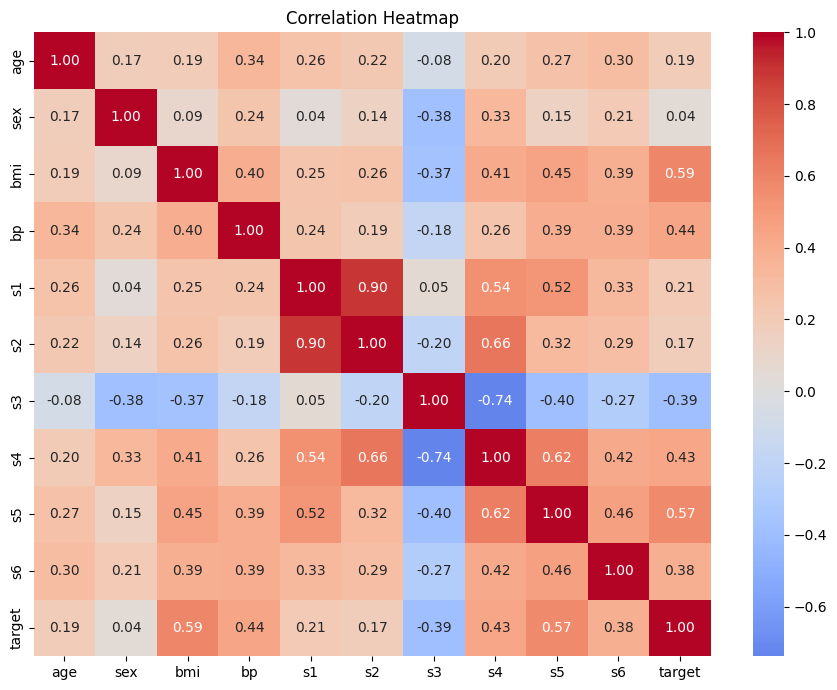


Association of each independent variable with the dependent variable:

feature  pearson_r  p_value  significant (p<0.05) strength
    bmi      0.586  0.00000                  True   strong
     s5      0.566  0.00000                  True   strong
     bp      0.441  0.00000                  True moderate
     s4      0.430  0.00000                  True moderate
     s3     -0.395  0.00000                  True moderate
     s6      0.382  0.00000                  True moderate
     s1      0.212  0.00001                  True     weak
    age      0.188  0.00007                  True     weak
     s2      0.174  0.00024                  True     weak
    sex      0.043  0.36643                 False     weak


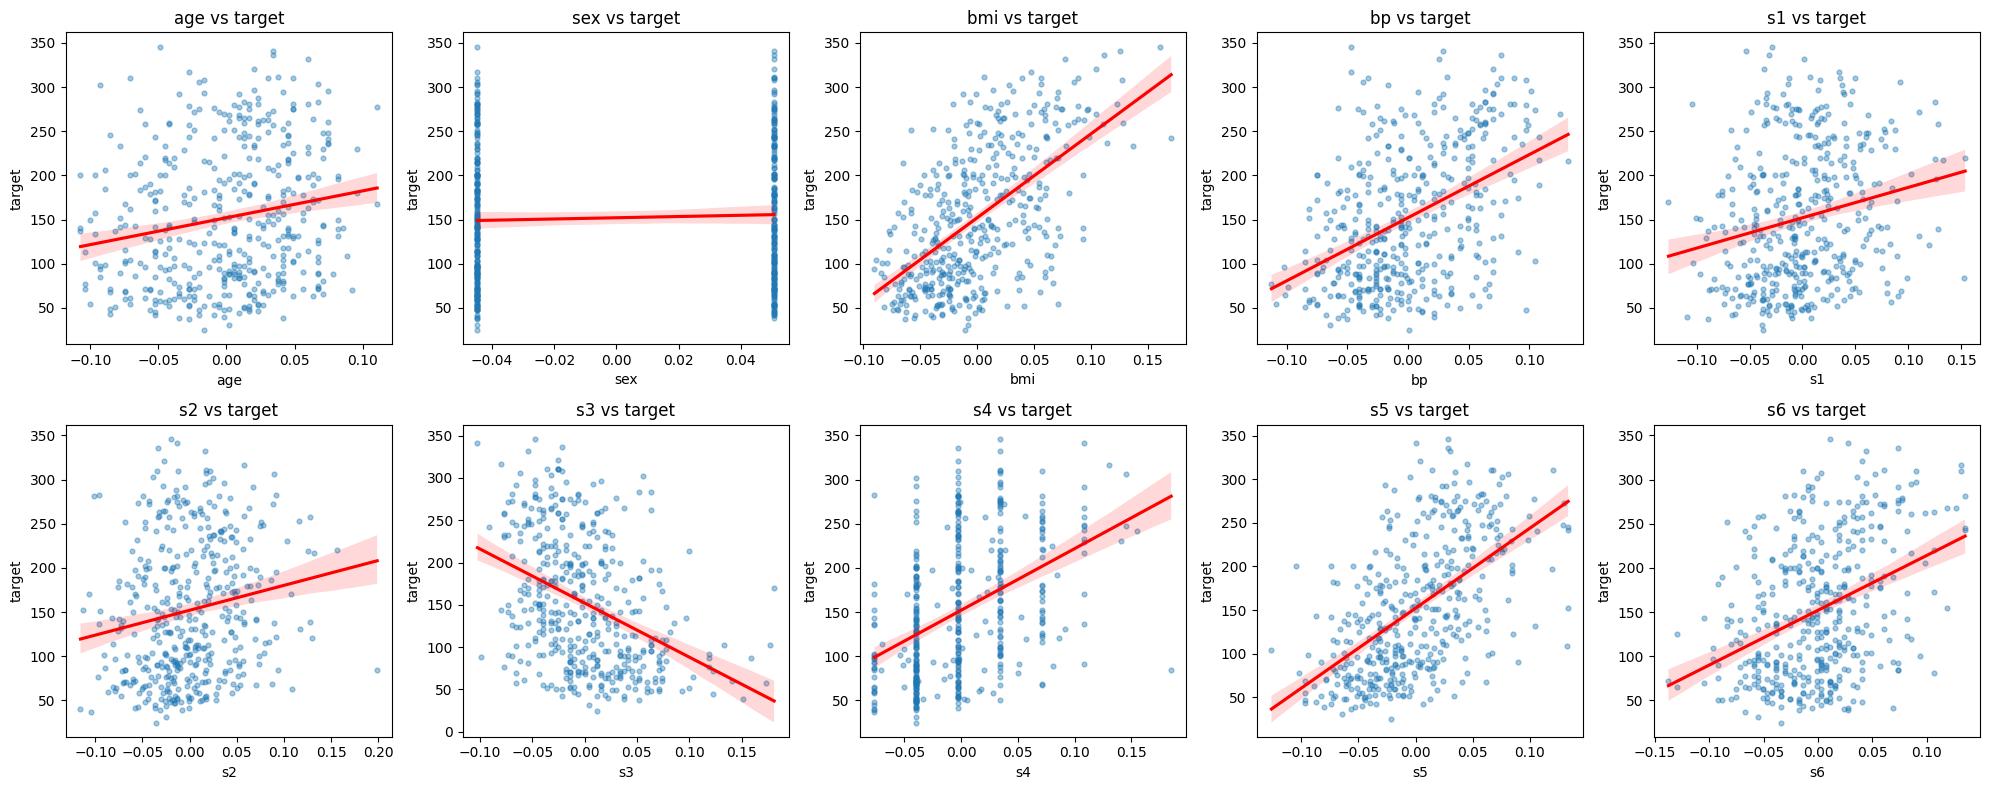


Intercept: 151.346

Regression coefficients:
 feature  coefficient
     s1     -931.489
     s5      736.199
    bmi      542.429
     s2      518.062
     bp      347.704
     s4      275.318
    sex     -241.964
     s3      163.420
     s6       48.671
    age       37.904

R^2 score : 0.453
RMSE      : 53.853


/tmp/ipykernel_3407/3052422584.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef, x="coefficient", y="feature", palette="viridis")


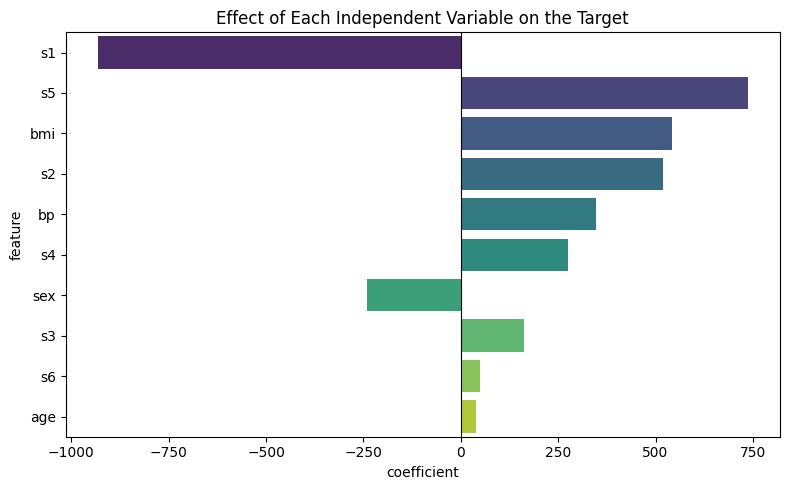


Conclusion: 'bmi' has the strongest linear association with the target (r = 0.586).
Positive r -> target increases as the feature increases; negative r -> target decreases.


In [ ]:
"""
Assignment 1: Identify the association between dependent and independent variables.

Approach:
  1. Load a dataset (diabetes: 10 independent features, 1 dependent target)
  2. Correlation matrix + heatmap (Pearson)
  3. Pearson r and p-value of each feature against the target
  4. Scatter plots with regression line for each feature vs target
  5. Multiple linear regression to see combined effect (coefficients, R^2)

Install: pip install pandas numpy matplotlib seaborn scipy scikit-learn
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

# ------------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------------
data = load_diabetes(as_frame=True)
df = data.frame.copy()          # features + 'target' column
target = "target"               # dependent variable (disease progression)
features = [c for c in df.columns if c != target]  # independent variables

print("Shape:", df.shape)
print("\nFirst 5 rows:\n", df.head())
print("\nSummary statistics:\n", df.describe().round(3))
print("\nMissing values:\n", df.isnull().sum())

# ------------------------------------------------------------------
# 2. Correlation matrix + heatmap
# ------------------------------------------------------------------
corr = df.corr(method="pearson")
print("\nCorrelation of each feature with target:\n",
      corr[target].drop(target).sort_values(ascending=False).round(3))

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 3. Pearson r and p-value (statistical significance)
# ------------------------------------------------------------------
rows = []
for col in features:
    r, p = stats.pearsonr(df[col], df[target])
    rows.append({
        "feature": col,
        "pearson_r": round(r, 3),
        "p_value": round(p, 5),
        "significant (p<0.05)": p < 0.05,
        "strength": ("strong" if abs(r) >= 0.5 else
                     "moderate" if abs(r) >= 0.3 else "weak"),
    })

assoc = pd.DataFrame(rows).sort_values("pearson_r", key=abs, ascending=False)
print("\nAssociation of each independent variable with the dependent variable:\n")
print(assoc.to_string(index=False))

# ------------------------------------------------------------------
# 4. Scatter plots with regression line
# ------------------------------------------------------------------
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, col in zip(axes.ravel(), features):
    sns.regplot(x=df[col], y=df[target], ax=ax,
                scatter_kws={"alpha": 0.4, "s": 12},
                line_kws={"color": "red"})
    ax.set_title(f"{col} vs {target}")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 5. Multiple linear regression (combined association)
# ------------------------------------------------------------------
X = df[features]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)

coef = pd.DataFrame({"feature": features, "coefficient": model.coef_})
coef = coef.sort_values("coefficient", key=abs, ascending=False)

print("\nIntercept:", round(model.intercept_, 3))
print("\nRegression coefficients:\n", coef.round(3).to_string(index=False))
print("\nR^2 score :", round(r2_score(y_test, y_pred), 3))
print("RMSE      :", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))

# Bar chart of coefficients
plt.figure(figsize=(8, 5))
sns.barplot(data=coef, x="coefficient", y="feature", palette="viridis")
plt.title("Effect of Each Independent Variable on the Target")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 6. Conclusion
# ------------------------------------------------------------------
top = assoc.iloc[0]
print(f"\nConclusion: '{top['feature']}' has the strongest linear association "
      f"with the target (r = {top['pearson_r']}).")
print("Positive r -> target increases as the feature increases; "
      "negative r -> target decreases.")